In [2]:
%pip install -q tensorflow keras pandas scikit-learn matplotlib seaborn visualkeras datasets


[notice] A new release of pip is available: 25.1.1 -> 25.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


# Module 5.1 Assignment - Transformer-based Sentiment Classification

> Submitted by Phillip Amir Esguerra

# 1. Loading IMDB Dataset

In [30]:
from datasets import load_dataset
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

In [6]:
dataset = load_dataset("imdb",  cache_dir="./.data")
print(dataset)

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    unsupervised: Dataset({
        features: ['text', 'label'],
        num_rows: 50000
    })
})


# 2. Dataset to DataFrame

In [17]:
def print_df_info(df, name="DataFrame"):
    print(f"========== {name} Sample Data ==========")
    print(df.head())
    print(f"\n========== {name} Data Info ==========")
    print(df.info())

In [18]:
train_df = pd.DataFrame(dataset['train'])
print_df_info(train_df, "Train DataFrame")

========== Train DataFrame Sample Data ==========
                                                text  label
0  I rented I AM CURIOUS-YELLOW from my video sto...      0
1  "I Am Curious: Yellow" is a risible and preten...      0
2  If only to avoid making this type of film in t...      0
3  This film was probably inspired by Godard's Ma...      0
4  Oh, brother...after hearing about this ridicul...      0

========== Train DataFrame Data Info ==========
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25000 entries, 0 to 24999
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   text    25000 non-null  object
 1   label   25000 non-null  int64 
dtypes: int64(1), object(1)
memory usage: 390.8+ KB
None


In [19]:
test_df = pd.DataFrame(dataset['test'])
print_df_info(test_df, "Test DataFrame")

========== Test DataFrame Sample Data ==========
                                                text  label
0  I love sci-fi and am willing to put up with a ...      0
1  Worth the entertainment value of a rental, esp...      0
2  its a totally average film with a few semi-alr...      0
3  STAR RATING: ***** Saturday Night **** Friday ...      0
4  First off let me say, If you haven't enjoyed a...      0

========== Test DataFrame Data Info ==========
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25000 entries, 0 to 24999
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   text    25000 non-null  object
 1   label   25000 non-null  int64 
dtypes: int64(1), object(1)
memory usage: 390.8+ KB
None


In [20]:
unsupervised_df = pd.DataFrame(dataset['unsupervised'])
print_df_info(unsupervised_df, "Unsupervised DataFrame")

========== Unsupervised DataFrame Sample Data ==========
                                                text  label
0  This is just a precious little diamond. The pl...     -1
1  When I say this is my favourite film of all ti...     -1
2  I saw this movie because I am a huge fan of th...     -1
3  Being that the only foreign films I usually li...     -1
4  After seeing Point of No Return (a great movie...     -1

========== Unsupervised DataFrame Data Info ==========
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   text    50000 non-null  object
 1   label   50000 non-null  int64 
dtypes: int64(1), object(1)
memory usage: 781.4+ KB
None


# 3. Exploratory Data Analysis

In [38]:
def create_eda_plot(df, name):
    figure, axes = plt.subplots(1,2, figsize=(15, 5))
    axes = axes.flatten()
    
    axes[0].set_title(f"{name} 'label' Distribution")
    sns.countplot(x="label", data=df, ax=axes[0])
    axes[0].set_xlabel("Label")
    axes[0].set_ylabel("Count")
    axes[0].grid(axis='y')
    
    df['review_length'] = df['text'].apply(len)
    axes[1].set_title(f"{name} Review Length Distribution")
    sns.histplot(df['review_length'], bins=50, kde=True, ax=axes[1])
    axes[1].set_xlabel("Review Length (characters)")
    axes[1].set_ylabel("Frequency")
    axes[1].grid(axis='y')

def create_eda(df, name):
    print(f"========== {name} EDA ==========")
    print(f"Number of samples: {len(df)}")
    print(f"Number of positive reviews: {len(df[df['label'] == 1])}")
    print(f"Number of negative reviews: {len(df[df['label'] == 0])}")
    print(f"Average review length: {df['text'].apply(len).mean()} characters")
    print(f"Average review word count: {df['text'].apply(lambda x: len(x.split())).mean()} words")
    
    create_eda_plot(df, name)

========== Train DataFrame EDA ==========
Number of samples: 25000
Number of positive reviews: 12500
Number of negative reviews: 12500
Average review length: 1325.06964 characters
Average review word count: 233.7872 words


/Users/Shared/_ws/nus-gen-ai/.venv/lib/python3.12/site-packages/scipy/_lib/_util.py:1272: RuntimeWarning: divide by zero encountered in vecdot
  return np.vecdot(x1, x2, axis=axis)
/Users/Shared/_ws/nus-gen-ai/.venv/lib/python3.12/site-packages/scipy/_lib/_util.py:1272: RuntimeWarning: overflow encountered in vecdot
  return np.vecdot(x1, x2, axis=axis)
/Users/Shared/_ws/nus-gen-ai/.venv/lib/python3.12/site-packages/scipy/_lib/_util.py:1272: RuntimeWarning: invalid value encountered in vecdot
  return np.vecdot(x1, x2, axis=axis)


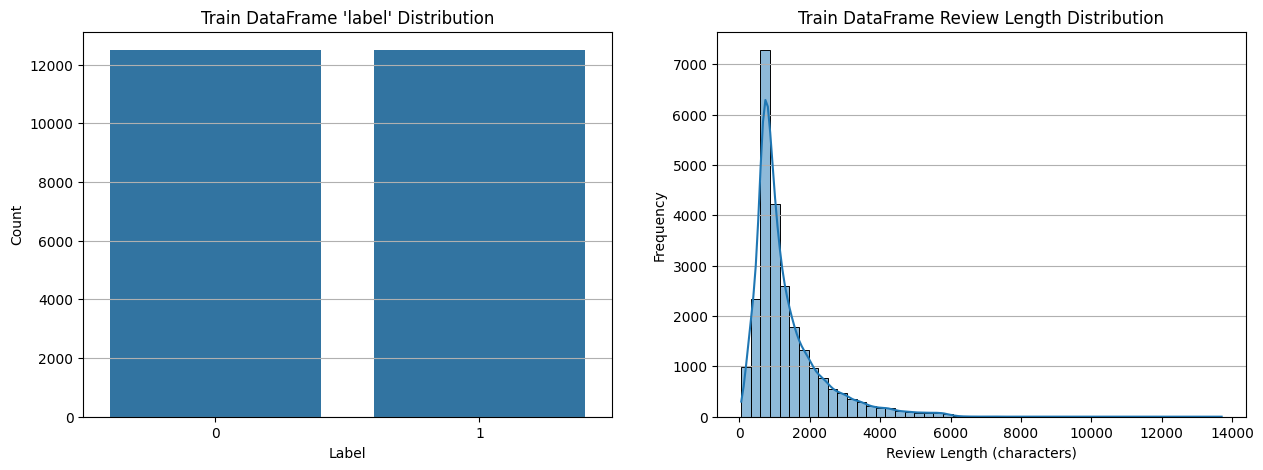

In [40]:
create_eda(train_df, "Train DataFrame")

========== Test DataFrame EDA ==========
Number of samples: 25000
Number of positive reviews: 12500
Number of negative reviews: 12500
Average review length: 1293.7924 characters
Average review word count: 228.52668 words


/Users/Shared/_ws/nus-gen-ai/.venv/lib/python3.12/site-packages/scipy/_lib/_util.py:1272: RuntimeWarning: divide by zero encountered in vecdot
  return np.vecdot(x1, x2, axis=axis)
/Users/Shared/_ws/nus-gen-ai/.venv/lib/python3.12/site-packages/scipy/_lib/_util.py:1272: RuntimeWarning: overflow encountered in vecdot
  return np.vecdot(x1, x2, axis=axis)
/Users/Shared/_ws/nus-gen-ai/.venv/lib/python3.12/site-packages/scipy/_lib/_util.py:1272: RuntimeWarning: invalid value encountered in vecdot
  return np.vecdot(x1, x2, axis=axis)


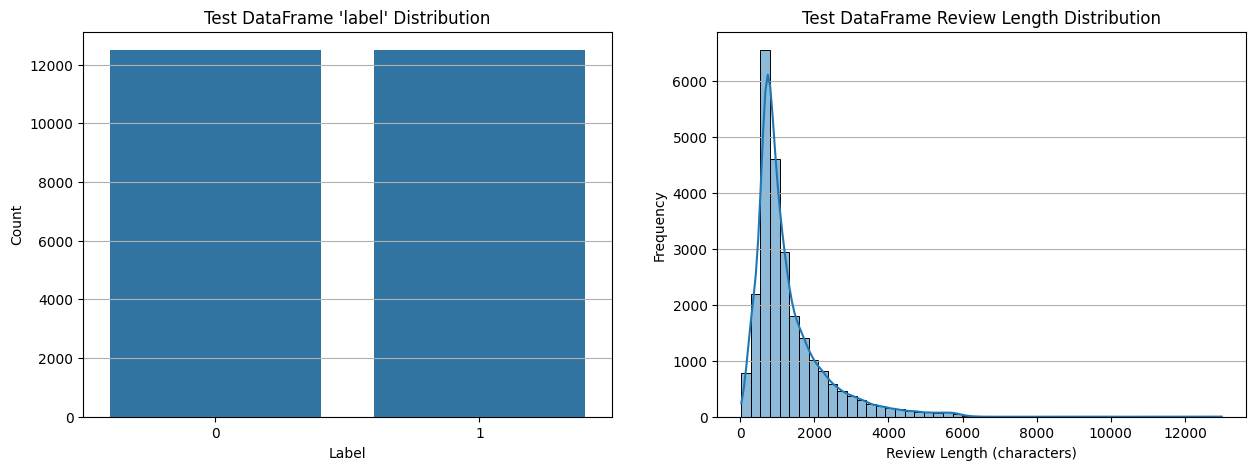

In [41]:
create_eda(test_df, "Test DataFrame")

In [ ]:
print("Missing values in training data:")
print(train_df.isnull().sum())

Missing values in each column:
text             0
label            0
review_length    0
dtype: int64


In [43]:
print("Missing values in test data:")
print(test_df.isnull().sum())

Missing values in test data:
text             0
label            0
review_length    0
dtype: int64


# 4. Checking for Missing and Outlier Data

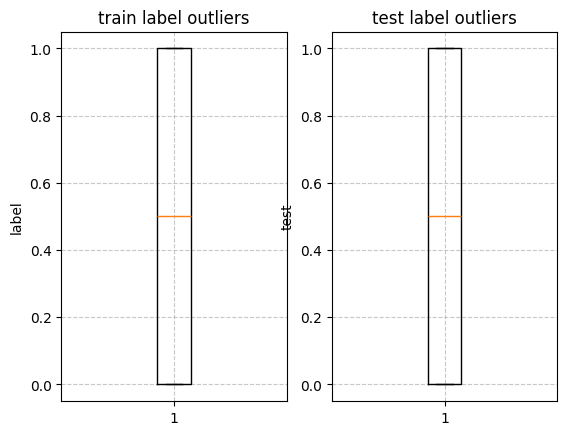

In [46]:
fig, axes = plt.subplots(1, 2)
axes = axes.flatten()

axes[0].boxplot(train_df["label"])
axes[0].set_title("train label outliers")
axes[0].set_ylabel("label")
axes[0].grid(True, linestyle="--", alpha=0.7)

axes[1].boxplot(test_df["label"])
axes[1].set_title("test label outliers")
axes[1].set_ylabel("test")
axes[1].grid(True, linestyle="--", alpha=0.7)

plt.show()

# 5. Text Tokenization